# Capítulo 2 · Marco referencial

Escribe en `../figures/` las tres figuras de la representación.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchaudio

sys.path.insert(0, str(next(p for p in Path.cwd().parents if (p / "pyproject.toml").exists()) / "src"))
from core.config import P
from models.frontend import FRONTENDS
from prepare_data import select_experiment
from utils.audio import hz_to_y, y_to_hz
from utils.figuras import (AMBAR, ANCHO, AZUL, GRIS, MEL, Salidas, anotaciones, anotada, caja, cargar, imagen,
                           leyenda)

OUT = Salidas("02_marco_referencial")
annotations = anotaciones()
experiment = select_experiment(annotations)[0]
lw = annotations[annotations.label == "lw/cs"]
note = lw.loc[(lw.duration_s - lw.duration_s.median()).abs().idxmin()]  # la sílaba de duración mediana

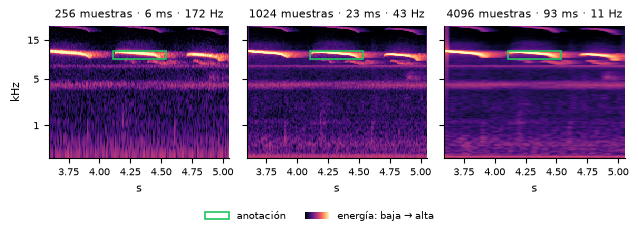

In [2]:
# El compromiso de la STFT: la misma sílaba con tres longitudes de trama
pad = max(note.duration_s * 1.2, 0.35)
start, length = max(note.begin_time_s - pad, 0.0), note.duration_s + 2 * pad
wave = cargar(note.audio_path, start, length)
fig, axes = plt.subplots(1, 3, figsize=(ANCHO, 2.2), sharey=True, layout="constrained")
for ax, win in zip(axes, (256, P.win_length, 4096)):
    mel = torchaudio.transforms.MelSpectrogram(
        P.target_sr, n_fft=P.n_fft, win_length=win, hop_length=P.hop_length, n_mels=P.n_mels,
        f_min=P.f_min, f_max=P.f_max, mel_scale=P.mel_scale)
    imagen(ax, 10 * torch.log10(mel(wave) + P.eps).numpy(), start, length)
    caja(ax, note.begin_time_s, note.end_time_s, note.low_freq_hz, note.high_freq_hz)
    ax.set_title(f"{win} muestras · {1000 * win / P.target_sr:.0f} ms · {P.target_sr / win:.0f} Hz")
for ax in axes[1:]:
    ax.set_ylabel("")
leyenda(fig, anotada(), energia=True)
OUT.figura(fig, "stft_tradeoff")

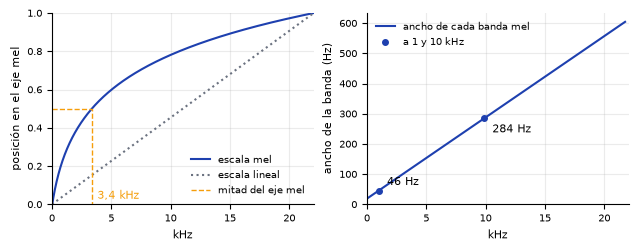

In [3]:
# La escala mel: posición en el eje y ancho de cada banda
khz = np.linspace(0, P.f_max, 2000) / 1000
edges = y_to_hz(np.linspace(0, 1, P.n_mels + 1), P)
centres, widths = (edges[:-1] + edges[1:]) / 2000, np.diff(edges)
half = float(y_to_hz(np.array([0.5]), P)[0]) / 1000
fig, (left, right) = plt.subplots(1, 2, figsize=(ANCHO, 2.4), layout="constrained")
left.plot(khz, hz_to_y(khz * 1000, P), color=AZUL, label="escala mel")
left.plot([0, khz[-1]], [0, 1], color=GRIS, ls=":", label="escala lineal")
left.plot([0, half, half], [0.5, 0.5, 0], color=AMBAR, ls="--", lw=1, label="mitad del eje mel")
left.annotate(f"{half:.1f} kHz".replace(".", ","), (half, 0), xytext=(4, 4), textcoords="offset points",
              color=AMBAR)
left.set(xlim=(0, khz[-1]), ylim=(0, 1), xlabel="kHz", ylabel="posición en el eje mel")
left.legend(loc="lower right")
right.plot(centres, widths, color=AZUL, label="ancho de cada banda mel")
for target in (1.0, 10.0):
    i = int(np.argmin(np.abs(centres - target)))
    right.plot(centres[i], widths[i], "o", color=AZUL, ms=4, label="a 1 y 10 kHz" if target < 5 else None)
    right.annotate(f"{widths[i]:.0f} Hz", (centres[i], widths[i]), xytext=(6, 4 if target < 5 else -10),
                   textcoords="offset points")
right.set(xlim=(0, khz[-1]), ylim=(0, None), xlabel="kHz", ylabel="ancho de la banda (Hz)")
right.legend(loc="upper left")
OUT.figura(fig, "mel_axis")

/tmp/ipykernel_7611/2336904737.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return float(np.percentile(np.log(MEL(cargar(r.audio_path, max(r.begin_time_s - 1.0, 0.0))) + P.eps), 25))


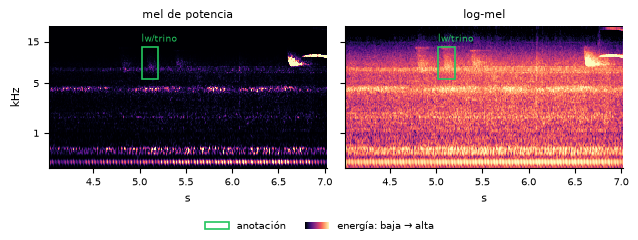

In [4]:
# El mel de potencia sin comprimir y el log-mel sobre la ventana más ruidosa de 24 trinos de LW,
# cada uno con la normalización por lote que ve el AST (PCEN se descartó)
def floor(r) -> float:
    return float(np.percentile(np.log(MEL(cargar(r.audio_path, max(r.begin_time_s - 1.0, 0.0))) + P.eps), 25))


trinos = experiment[experiment.label == "lw/trino"].sample(24, random_state=7)
noisiest = max(trinos.itertuples(), key=floor)
start = max(noisiest.begin_time_s - 1.0, 0.0)
power = MEL(cargar(noisiest.audio_path, start))[None, None]
fig, axes = plt.subplots(1, 2, figsize=(ANCHO, 2.3), sharey=True, layout="constrained")
for ax, (name, title) in zip(axes, [("none", "mel de potencia"), ("logmel", "log-mel")]):
    with torch.no_grad():
        imagen(ax, FRONTENDS[name](P.n_mels)(power)[0, 0].numpy(), start, P.clip_len_s)
    caja(ax, noisiest.begin_time_s, noisiest.end_time_s, noisiest.low_freq_hz, noisiest.high_freq_hz,
         texto="lw/trino")
    ax.set_title(title)
axes[1].set_ylabel("")
leyenda(fig, anotada(), energia=True)
OUT.figura(fig, "frontends")